# 01 — Exploratory data analysis: MPEA dataset, Vickers hardness

**Data:** Borg et al., *Expanded dataset of mechanical properties and observed phases of
multi-principal element alloys*, Sci. Data 7, 430 (2020).
File `data/MPEA_dataset.csv` (pinned commit, see `scripts/download_data.py`).

**Goal of this notebook.** Before fitting anything, answer five questions whose answers
decide how the modelling has to be set up:

1. How many rows have a hardness (HV) value, and how many *distinct compositions* is that?
2. What does the HV distribution look like; are there outliers?
3. Which elements appear, and how often?
4. Would duplicate compositions leak across a random train/test split?
5. What fraction of rows report a phase / microstructure?

Each question has a code section followed by a short **Answer** in markdown.

In [1]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pymatgen.core import Composition
from sklearn.model_selection import KFold

# Make the repo root importable so we can reuse hea_ml/ (the same loading code
# the CV demo uses — one definition of "the dataset", not two).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from hea_ml.data import load_raw, load_hardness, normalize_formula

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)
raw = load_raw()
print(raw.shape)
raw.head(3)

(1545, 23)


,ref_id,formula,microstructure,processing,phase_class,PROPERTY: grain size ($\mu$m),PROPERTY: Exp. Density (g/cm$^3$),PROPERTY: Calculated Density (g/cm$^3$),HV,test_type,...,PROPERTY: Elongation (%),PROPERTY: Elongation plastic (%),PROPERTY: Exp. Young modulus (GPa),PROPERTY: Calculated Young modulus (GPa),PROPERTY: O content (wppm),PROPERTY: N content (wppm),PROPERTY: C content (wppm),doi,year,REFERENCE: title
0,27,Al0.25 Co1 Fe1 Ni1,FCC,CAST,FCC,NaN,NaN,7.9,138.0,C,...,NaN,NaN,NaN,192.0,NaN,NaN,NaN,10.1016/j.jmmm.2014.07.023,2014,Effects of Al and Si addition on the structure and prope...
1,27,Al0.5 Co1 Fe1 Ni1,FCC+BCC,CAST,other,NaN,NaN,7.4,212.0,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.1016/j.jmmm.2014.07.023,2014,Effects of Al and Si addition on the structure and prope...
2,27,Al0.75 Co1 Fe1 Ni1,FCC+BCC,CAST,other,NaN,NaN,7.0,385.0,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.1016/j.jmmm.2014.07.023,2014,Effects of Al and Si addition on the structure and prope...


## Q1. Rows with HV vs distinct compositions

The dataset is a *literature compilation*: each row is one measurement reported in one paper.
The same alloy can therefore appear many times (different papers, different heat treatments,
or one paper reporting several conditions). Counting **rows** overstates how much independent
information we have; counting **distinct compositions** is closer to the truth for a model
whose only input is composition.

"Distinct" needs a definition. Papers write ratios differently (`Al0.5 Co1 ...` vs
`Al1 Co2 ...`), so we compare the *normalized* key from `hea_ml.data.normalize_formula`:
atomic fractions, rounded, elements sorted.

In [2]:
has_hv = raw[raw["HV"].notna()].copy()
has_hv["comp_key"] = has_hv["formula"].map(normalize_formula)

print(f"rows in file                         : {len(raw)}")
print(f"rows with HV                         : {len(has_hv)}")
print(f"distinct raw formula strings (HV)    : {has_hv['formula'].nunique()}")
print(f"distinct normalized compositions (HV): {has_hv['comp_key'].nunique()}")

rows in file                         : 1545
rows with HV                         : 530
distinct raw formula strings (HV)    : 377
distinct normalized compositions (HV): 377


HV is not always measured at room temperature. Hardness falls with temperature, so a row
measured at 800 °C is effectively a *different target*. Let's look:

In [3]:
print(has_hv["test_temp_C"].value_counts(dropna=False).sort_index())
print()
print("HV by whether a temperature is recorded:")
print(has_hv.groupby(has_hv["test_temp_C"].isna().map({True: "no temp", False: "temp given"}))["HV"]
      .describe()[["count", "mean", "50%", "std"]])

test_temp_C
25.0      386
200.0       4
300.0       1
340.0       1
400.0       4
430.0       1
600.0       7
700.0       2
800.0       8
1000.0      1
NaN       115
Name: count, dtype: int64

HV by whether a temperature is recorded:
             count        mean    50%         std
test_temp_C                                      
no temp      115.0  540.933043  509.0  255.414760
temp given   415.0  460.888675  461.0  196.361869


In [4]:
# The modelling subset used everywhere downstream (see load_hardness docstring):
# HV present, tested at 25 °C or temperature not stated.
df = load_hardness()
print(f"modelling rows: {len(df)}   distinct compositions: {df['comp_key'].nunique()}")

modelling rows: 501   distinct compositions: 376


**Sensitivity of "distinct" to the rounding choice.** If rounding is too fine, two papers'
nominal vs measured composition of the *same* alloy (e.g. `Al0.3` vs `Al0.304`) count as
different; too coarse and genuinely different alloys merge.

In [5]:
for d in (2, 3, 4):
    n = df["formula"].map(lambda f: normalize_formula(f, d)).nunique()
    print(f"round to {d} decimals of atomic fraction -> {n} distinct compositions")

# Show what 2-decimal rounding would merge across the *whole* file:
k2 = raw["formula"].map(lambda f: normalize_formula(f, 2))
merged = raw.groupby(k2)["formula"].unique()
merged = merged[merged.map(len) > 1]
print(f"\n{len(merged)} groups of different raw strings merge at 2 decimals, e.g.:")
for key, forms in merged.head(6).items():
    print("  ", list(forms))

round to 2 decimals of atomic fraction -> 372 distinct compositions
round to 3 decimals of atomic fraction -> 376 distinct compositions
round to 4 decimals of atomic fraction -> 376 distinct compositions

12 groups of different raw strings merge at 2 decimals, e.g.:
   ['Al0.3 Co1 Cr1 Fe1 Ni1', 'Al0.304 Co1 Cr1 Fe1 Ni1']
   ['Al0.49 Co1 Cr1 Fe1 Mn1 Ni1', 'Al0.5 Co1 Cr1 Fe1 Mn1 Ni1']
   ['Al0.68 Co1 Cr1 Fe1 Mn1 Ni1', 'Al0.7 Co1 Cr1 Fe1 Mn1 Ni1']
   ['Al0.5 Cr0.5 Cu0.5 Fe0.5 Ni1', 'Al0.515 Cr0.515 Cu0.515 Fe0.515 Ni1']
   ['Al0.515 Cr0.515 Fe1 Ni1', 'Al0.5 Cr0.5 Fe1 Ni1']
   ['Co1 Cr1 Fe1 Mn1 Ni1 V0.75', 'Co1 Cr1 Fe1 Mn1 Ni1 V0.765']


### Answer — Q1

* **530 of 1,545 rows (34 %)** report HV. They cover **377 distinct compositions**.
* 29 of those rows were measured at elevated temperature (200–1000 °C). We drop them, leaving
  **501 rows / 376 distinct compositions** for modelling. 115 rows give no test temperature; we
  *assume* room temperature. That is a judgement call: the no-temperature group has a higher
  mean HV (541 vs 461), but it is also dominated by multi-phase ("other") alloys from 20 papers,
  so the difference is plausibly *which alloys* rather than *what temperature*. Worth revisiting.
* So we have **~1.33 rows per composition**: roughly a quarter of the rows are repeats.
  With only ~376 independent compositions and 136 features, overfitting is a real risk.
* The count is fairly robust to the rounding choice (372–376). In this file, at 3 decimals,
  every distinct composition already has a single spelling, but at 2 decimals some
  *near-duplicates* merge (`Al0.3` vs `Al0.304`, `V0.75` vs `V0.765`) — almost certainly
  nominal vs measured compositions of the same alloy. Keep this in mind for Q4: grouping at
  3 decimals leaves those near-twins in separate groups, so even a grouped split is *slightly*
  optimistic. 2-decimal grouping is a stricter alternative to try later.

## Q2. HV distribution and outliers

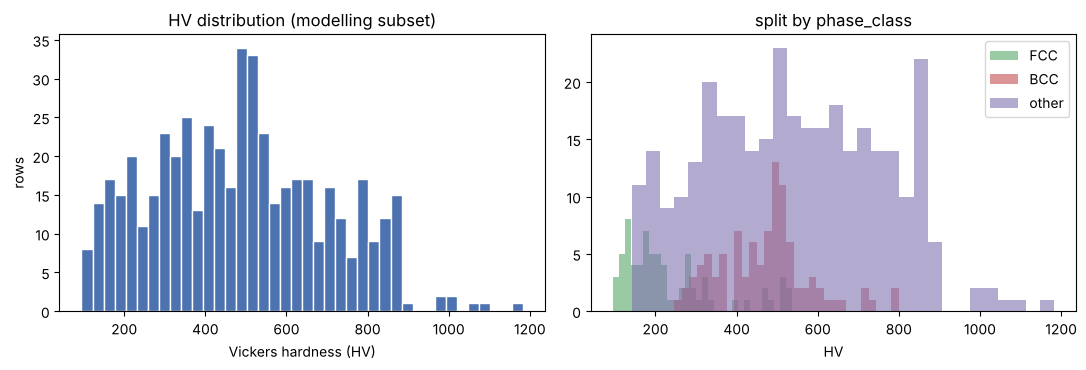

count     501.0
mean      482.8
std       215.6
min        94.7
25%       318.9
50%       485.0
75%       633.0
max      1183.0
Name: HV, dtype: float64
skewness: 0.30
phase_class
BCC      484.0
FCC      197.0
other    535.0
Name: HV, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["HV"], bins=40, color="#4C72B0", edgecolor="white")
axes[0].set(xlabel="Vickers hardness (HV)", ylabel="rows", title="HV distribution (modelling subset)")

# Colour by the coarse phase label: crystal structure is the biggest single
# driver of hardness, so this should show *why* the distribution is wide.
for label, colour in [("FCC", "#55A868"), ("BCC", "#C44E52"), ("other", "#8172B2")]:
    axes[1].hist(df.loc[df["phase_class"] == label, "HV"], bins=30, alpha=0.6, label=label, color=colour)
axes[1].set(xlabel="HV", title="split by phase_class")
axes[1].legend()
plt.tight_layout()
plt.show()

print(df["HV"].describe().round(1))
print(f"skewness: {df['HV'].skew():.2f}")
print(df.groupby("phase_class")["HV"].median().round(0))

In [7]:
# Outliers via Tukey's IQR rule: flag points beyond 1.5 * IQR from the quartiles.
# This is a *screening* rule, not a deletion rule: a flagged point might be a
# typo, or it might be the most interesting alloy in the set.
q1, q3 = df["HV"].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"IQR fences: [{lo:.0f}, {hi:.0f}] HV")
print(df[(df["HV"] < lo) | (df["HV"] > hi)][["formula", "HV", "microstructure", "processing", "doi"]])
print("\nTop 8 and bottom 5 for a sanity check:")
cols = ["formula", "HV", "microstructure", "processing"]
print(df.nlargest(8, "HV")[cols].to_string())
print(df.nsmallest(5, "HV")[cols].to_string())

IQR fences: [-152, 1104] HV
             formula      HV microstructure processing                            doi
276  Al1 Co1 Cr1 Ni1  1183.0         BCC+B2       CAST  10.1016/j.jallcom.2018.11.057

Top 8 and bottom 5 for a sanity check:
                            formula      HV  microstructure processing
276                 Al1 Co1 Cr1 Ni1  1183.0          BCC+B2       CAST
407  Al1 Co1 Cr0.091 Nb0.727 W0.212  1084.0             NaN       CAST
277           Cr1 Mo1 Nb1 Ta1 V1 W1  1072.0  BCC+Laves+Sec.     POWDER
408    Co1 Cr0.917 Ni1 Ta0.5 Ti0.75  1011.0             NaN       CAST
278           Cr1 Mo1 Nb1 Ta1 V1 W1  1010.0  BCC+Laves+Sec.     POWDER
279           Cr1 Mo1 Nb1 Ta1 V1 W1   991.3  BCC+Laves+Sec.     POWDER
280           Cr1 Mo1 Nb1 Ta1 V1 W1   988.3  BCC+Laves+Sec.     POWDER
104             Al1 Cr1 Fe1 Mo1 Ni1   905.0         B2+Sec.       CAST
                           formula     HV microstructure processing
271                Co1 Cr1 Fe1 Ni1   94.7            

**Within-composition spread = a noise floor.** For compositions measured more than once, the
spread of HV *between rows of the same composition* is variation that composition alone cannot
explain (processing, grain size, lab-to-lab differences). That puts a rough lower bound on the
error any composition-only model can honestly achieve.

In [8]:
counts = df["comp_key"].value_counts()
repeated = df[df["comp_key"].map(counts) > 1]
within_sd = repeated.groupby("comp_key")["HV"].std()
print(f"compositions with >1 row: {len(within_sd)}")
print(f"median within-composition SD : {within_sd.median():.0f} HV")
print(f"mean   within-composition SD : {within_sd.mean():.0f} HV")
print(f"overall SD of HV             : {df['HV'].std():.0f} HV")

# The most-repeated alloy, to make the spread concrete:
top = counts.index[0]
print(f"\nAll rows for {top}:")
print(df.loc[df["comp_key"] == top, ["formula", "HV", "processing", "microstructure", "doi"]].to_string())

compositions with >1 row: 59
median within-composition SD : 44 HV
mean   within-composition SD : 51 HV
overall SD of HV             : 216 HV

All rows for Al0.200 Co0.200 Cr0.200 Fe0.200 Ni0.200:
                 formula     HV processing microstructure                             doi
25   Al1 Co1 Cr1 Fe1 Ni1  484.0     ANNEAL            BCC   10.1016/j.jallcom.2009.08.090
26   Al1 Co1 Cr1 Fe1 Ni1  433.0     ANNEAL        FCC+BCC   10.1016/j.jallcom.2009.08.090
44   Al1 Co1 Cr1 Fe1 Ni1  395.0       CAST            BCC   10.1016/j.jallcom.2008.07.124
52   Al1 Co1 Cr1 Fe1 Ni1  520.0       CAST            BCC      10.1016/j.msea.2011.10.110
337  Al1 Co1 Cr1 Fe1 Ni1  519.0       CAST         B2+BCC   10.1016/j.matchar.2019.03.006
338  Al1 Co1 Cr1 Fe1 Ni1  493.0       CAST         B2+BCC   10.1016/j.matchar.2019.03.006
380  Al1 Co1 Cr1 Fe1 Ni1  550.0     POWDER        BCC+FCC   10.1016/j.matchar.2019.05.022
381  Al1 Co1 Cr1 Fe1 Ni1  510.0     POWDER        BCC+FCC   10.1016/j.matchar.2019.0

### Answer — Q2

* HV spans **~95 to 1,183 HV**, median ≈ 485, mean ≈ 483, SD ≈ 216. The shape is broad and
  only mildly right-skewed (skew ≈ 0.3) — no log-transform needed for now.
* The width is mostly **structure**: FCC alloys sit low (median ≈ 197 HV), BCC (≈ 484) and
  multi-phase/unknown "other" (≈ 535) much higher. A model that can infer "FCC-ish vs BCC-ish" from
  composition (VEC is designed for exactly this) gets most of the variance.
* **Outliers:** the IQR rule flags only **one** row: AlCoCrNi at 1,183 HV (BCC+B2, cast).
  The next-highest rows (CrMoNbTaVW ≈ 990–1,070 HV, Laves-containing, powder-processed) are
  physically plausible for refractory / intermetallic-laden alloys. Nothing looks like a
  units error, so **keep all rows**; maybe re-check the 1,183 value against its paper later.
* **Noise floor:** among repeated compositions the median within-composition SD is
  **≈ 44 HV** (mean ≈ 51). The same equiatomic AlCoCrFeNi ranges 395–550 HV across 10 rows.
  So a composition-only model should not be expected to beat roughly **40–50 HV error**; an
  MAE much below that should make you suspicious of leakage, not happy.

## Q3. Element frequency

Counted over **distinct compositions** (not rows), so a heavily repeated alloy doesn't inflate
its elements.

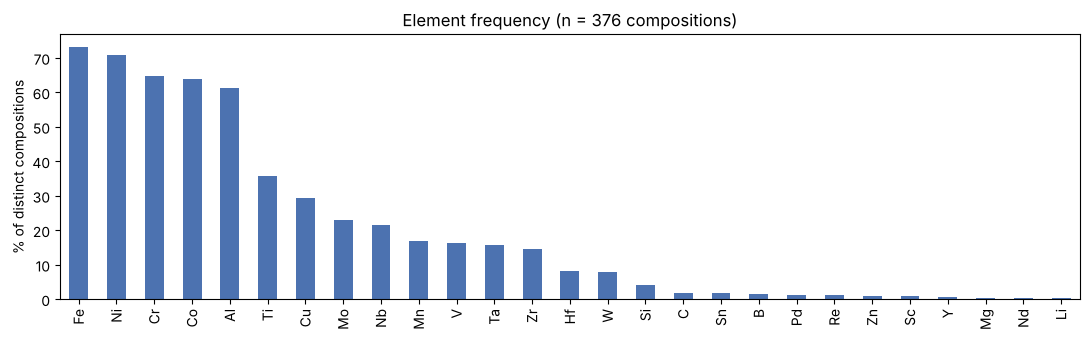

Fe    275
Ni    266
Cr    244
Co    240
Al    230
Ti    134
Cu    110
Mo     86
Nb     81
Mn     63
V      61
Ta     59
Zr     55
Hf     31
W      30
Si     15
C       7
Sn      7
B       6
Pd      5
Re      5
Zn      3
Sc      3
Y       2
Mg      1
Nd      1
Li      1

elements per alloy: {3: 6, 4: 55, 5: 146, 6: 135, 7: 30, 8: 3, 9: 1}


In [9]:
elem_counts = Counter()
for key in df["comp_key"].unique():
    elem_counts.update(el.symbol for el in Composition(key).elements)
elem_freq = pd.Series(elem_counts).sort_values(ascending=False)
n_comp = df["comp_key"].nunique()

fig, ax = plt.subplots(figsize=(11, 3.5))
(elem_freq / n_comp * 100).plot.bar(ax=ax, color="#4C72B0")
ax.set(ylabel="% of distinct compositions", title=f"Element frequency (n = {n_comp} compositions)")
plt.tight_layout()
plt.show()
print(elem_freq.to_string())

n_el = pd.Series([len(Composition(k).elements) for k in df["comp_key"].unique()])
print("\nelements per alloy:", n_el.value_counts().sort_index().to_dict())

### Answer — Q3

* **27 elements** occur, but very unevenly. The 3d "Cantor family" dominates: **Fe (73 %),
  Ni (71 %), Cr (65 %), Co (64 %), Al (61 %)** of compositions. Next tier: Ti, Cu, Mo, Nb, Mn,
  V, Ta, Zr (15–36 %), i.e. the refractory HEAs. Hf and W ~8 %.
* A long tail (Si, Sn, C, B, Re, Pd, Sc, Zn, Y, Nd, Li, Mg) appears in **≤ 15 compositions
  each, several only once**. The model has essentially no evidence about these elements;
  predictions for alloys containing them are extrapolations. This is also why a random split
  flatters the model: rare-element alloys rarely end up alone in the test set.
* Most alloys have 4–6 elements, as expected for HEAs.

## Q4. Would duplicate compositions leak across a random split?

"Leakage" here means: the *same alloy* is in both train and test. Then the model can score well
by recognising the composition (memorising its HV) rather than by learning chemistry → hardness
relationships that transfer to **new** alloys, which is the actual use case.

We measure it directly: do a 5-fold random `KFold` exactly as the demo script does, and for each
test fold count how many test rows have their composition also in the training folds.

In [10]:
print("rows per composition:", counts.value_counts().sort_index().to_dict())
print(f"rows that belong to a repeated composition: {(df['comp_key'].map(counts) > 1).sum()} "
      f"of {len(df)} ({(df['comp_key'].map(counts) > 1).mean():.0%})")

leak_fracs = []
for train_idx, test_idx in KFold(n_splits=5, shuffle=True, random_state=42).split(df):
    train_keys = set(df["comp_key"].iloc[train_idx])
    leak_fracs.append(df["comp_key"].iloc[test_idx].isin(train_keys).mean())
print(f"\nrandom 5-fold KFold: test rows whose composition is also in train = "
      f"{np.mean(leak_fracs):.0%} (per fold: {', '.join(f'{x:.0%}' for x in leak_fracs)})")

rows per composition: {1: 317, 2: 31, 3: 13, 4: 8, 5: 2, 6: 1, 7: 1, 9: 2, 10: 1}
rows that belong to a repeated composition: 184 of 501 (37%)

random 5-fold KFold: test rows whose composition is also in train = 35% (per fold: 33%, 42%, 33%, 35%, 31%)


### Answer — Q4

**Yes.** 184 of 501 rows (37 %) belong to a composition that appears more than once
(up to 10 times for AlCoCrFeNi). Under a random 5-fold split, **~35 % of test
rows have an identical composition in the training set.** For those rows a tree model can
effectively look up the answer, so random-split scores will be optimistic about performance on
genuinely new alloys.

The fix is to split by **group** (`GroupKFold` with `groups = comp_key`), so every row of a
composition lands in the same fold. `scripts/cv_split_demo.py` measures how large the
optimism actually is. Two caveats to carry forward:

* Near-duplicates (`Al0.3` vs `Al0.304`, Q1) and *composition series* (Al0.1…Al1.0 CoCrFeNi)
  still leak *some* information across groups. Grouping by alloy family or by paper are
  stricter options for later.
* The 59 repeated compositions' within-group spread (Q2) is what a grouped split forces the
  model to *predict* rather than *recall*.

## Q5. Fraction reporting a phase

Two phase-related columns exist:

* `microstructure` — free-ish text like `BCC`, `FCC+BCC`, `BCC+Laves`;
* `phase_class` — a coarse `BCC` / `FCC` / `other` label derived from it.

`phase_class` has **no missing values**, which is misleading: let's see what "other" hides.

In [11]:
print("microstructure missing, by phase_class (whole file):")
print(pd.crosstab(raw["microstructure"].isna().map({True: "missing", False: "reported"}), raw["phase_class"]))

for name, sub in [("whole file", raw), ("HV rows (all temps)", has_hv), ("modelling subset", df)]:
    print(f"\n{name:22s}: microstructure reported for {sub['microstructure'].notna().mean():.1%} "
          f"of {len(sub)} rows")

print("\nmodelling subset, microstructure (top 12):")
print(df["microstructure"].fillna("<missing>").value_counts().head(12).to_string())

microstructure missing, by phase_class (whole file):
phase_class     BCC  FCC  other
microstructure                 
missing           0    0    143
reported        468  265    669

whole file            : microstructure reported for 90.7% of 1545 rows

HV rows (all temps)   : microstructure reported for 84.5% of 530 rows

modelling subset      : microstructure reported for 83.6% of 501 rows

modelling subset, microstructure (top 12):
microstructure
BCC             97
<missing>       82
FCC             73
FCC+BCC         59
FCC+Sec.        42
BCC+Sec.        35
BCC+B2          26
Other           13
FCC+BCC+B2      12
FCC+BCC+Sec.    11
B2+Sec.          8
BCC+Laves        5


### Answer — Q5

* `microstructure` is reported for **90.7 % of all rows** but only **84.5 % of HV rows**
  (83.6 % of the modelling subset) — hardness papers are a bit less diligent
  about phase identification.
* **All 143 missing-microstructure rows are labelled `phase_class = "other"`.** So "other" mixes
  two very different things: genuinely multi-phase alloys (FCC+BCC, BCC+Laves, …) and
  "phase unknown". If phase is ever used as a feature or for stratification, treat missing
  explicitly instead of trusting `other`.
* Phase is *not* an input for the composition-only model (it's a measured outcome you wouldn't
  have for a new alloy), but it's valuable for diagnosing errors later — e.g. checking whether
  the model fails mainly on multi-phase alloys.

## Summary — what this means for modelling

| Finding | Consequence |
|---|---|
| 501 usable rows, only 376 distinct compositions | Small data. Prefer simple/regularised models; report CV mean ± std, not single splits. |
| ~1/3 of random-split test rows have their composition in train | Random `KFold` will be optimistic → use `GroupKFold` on `comp_key`. |
| Within-composition SD ≈ 44 HV | Treat ~40–50 HV MAE as a practical floor for composition-only models. |
| Fe/Ni/Cr/Co/Al dominate; many elements are rare | Expect poor extrapolation to alloys with rare elements. |
| `phase_class="other"` includes unknowns | Don't use it naïvely; handle missing microstructure explicitly. |